# DOE-025
## クロス直後、含み益が伸びない場合に許容できる含み損カウント

- 対象銘柄: 9984
- 実験パラメータ
    - PROFIT_THRESHOLD
        - 2, 4, 6, 8, 10
    - COUNT_NEGATIVE_PROFIT
        - 2, 4, 6, 8, 10 
- 固定パラメータ
    - TYPE_MA_1
        - EMA
    - PERIOD_MA_1
        - 60
    - PERIOD_MA_2（長周期移動平均線）
        - 900
    - LOSSCUT_SIMPLE（単純ロスカット）
        - -50
- MA1 / MA2 クロス・シグナルのエントリ・エグジット
- 評価指標
    - 収益と約定回数

In [1]:
from pathlib import Path

import pandas as pd

# === 実験番号 ===
name_doe = "doe-025"

# pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 300)

# 指定したディレクトリのPathオブジェクトを作成
dir_path = Path(f"../doe/{name_doe}")

# .glob() で .csv ファイルのリスト（イテレータ）を取得してリストに変換
list_csv_file = sorted([str(p) for p in dir_path.glob("*.csv") if p.is_file()])

# 集計対象の条件列
columns_group = [
    "TYPE_MA_1",
    "PROFIT_THRESHOLD",
    "COUNT_NEGATIVE_PROFIT",
]

# CSV ファイルを読み込んで結合
df = pd.concat(
    [pd.read_csv(file) for file in list_csv_file],
    ignore_index=True,
)

# 条件ごとに Profit を集計
df_total = df.groupby(columns_group, as_index=False).agg(
    Profit_Total=("Profit", "sum"),
    Profit_Median=("Profit", "median"),
    Transactions_Median=("Transactions", "median"),
)

print(df_total)
print("\n *** Past", len(list_csv_file), "days statistics ***")
print("\n△ Profit_Total Top 3")
print(df_total.nlargest(3, "Profit_Total"))
print("\n▼ Profit_Total Bottom 3")
print(df_total.nsmallest(3, "Profit_Total"))
print("\n\n△ Profit_Median Top 3")
print(df_total.nlargest(3, "Profit_Median"))
print("\n▼ Profit_Median Bottom 3")
print(df_total.nsmallest(3, "Profit_Median"))

   TYPE_MA_1  PROFIT_THRESHOLD  COUNT_NEGATIVE_PROFIT  Profit_Total  Profit_Median  Transactions_Median
0        EMA                 4                      4       -1257.0          -56.0                 48.0
1        EMA                 4                      8       -1252.0          -57.0                 48.0
2        EMA                 4                     12       -1252.0          -57.0                 48.0
3        EMA                 4                     16       -1252.0          -57.0                 48.0
4        EMA                 4                     20       -1252.0          -57.0                 48.0
5        EMA                 8                      4       -1234.0          -56.0                 48.0
6        EMA                 8                      8       -1252.0          -57.0                 48.0
7        EMA                 8                     12       -1252.0          -57.0                 48.0
8        EMA                 8                     16       -125

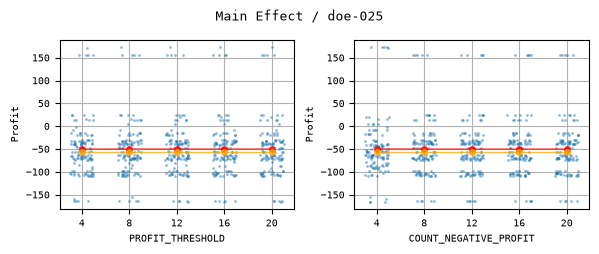

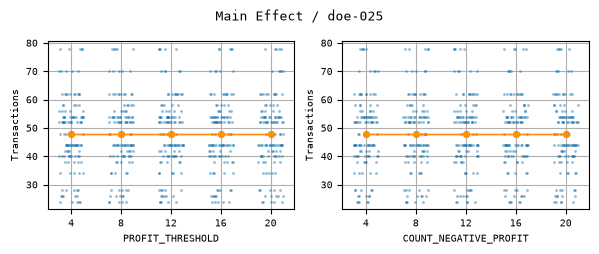

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["font.family"] = "monospace"
plt.rcParams["font.size"] = 7

cols_param = [
    "PROFIT_THRESHOLD",
    "COUNT_NEGATIVE_PROFIT",
]


for name_y in ["Profit", "Transactions"]:
    fig, axes = plt.subplots(1, 2, figsize=(6, 2.5))

    for ax, col in zip(axes.flatten(), cols_param):
        sns.stripplot(
            data=df,
            x=col,
            y=name_y,
            ax=ax,
            size=2,
            jitter=0.25,  # 横方向へのばらつき具合
            alpha=0.5,  # 重なりが見やすいよう少し透明に
            color="tab:blue",  # 散布図の色を指定
        )

        # x の各水準ごとの平均値
        mean = df.groupby(col)[name_y].mean()
        # stripplot の x 軸位置（0, 1, 2...）に合わせて線をつなぐ
        ax.plot(
            range(len(mean)),
            mean.values,
            "o-",
            color="red",
            markersize=4,
            linewidth=1,
            alpha=0.75,
            zorder=5,  # 点の裏に隠れないよう前面に描画
        )

        # x の各水準ごとのメジアン
        median = df.groupby(col)[name_y].median()
        # stripplot の x 軸位置（0, 1, 2...）に合わせて線をつなぐ
        ax.plot(
            range(len(median)),
            median.values,
            "o-",
            color="orange",
            markersize=4,
            linewidth=1,
            alpha=0.75,
            zorder=5,
        )

        ax.set(xlabel=col, ylabel=name_y)
        ax.grid(True)

    fig.suptitle(f"Main Effect / {name_doe}", fontsize=9)

    plt.tight_layout()
    pngfile = f"../doe/{name_doe}/main_effect_{name_y}.png"
    plt.savefig(pngfile)
    plt.show()